In [ ]:
!pip install astrospice
!pip install sunpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 39.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 50.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.9 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import zipfile

In [ ]:
zipped_file_path = '/content/drive/MyDrive/424ph2013_transferred/WI_H1_SWE_2018_2024.zip'

# Create extraction directory
extract_dir = '/content/wind_data_extracted'
os.makedirs(extract_dir, exist_ok=True)

# Extract the zip file
try:
    with zipfile.ZipFile(zipped_file_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    print(f" Files extracted to: {extract_dir}")
    print("\n Contents of extracted directory:")
    for file in os.listdir(extract_dir):
        print(f"   - {file}")
except Exception as e:
    print(f" Error extracting file: {e}")
    print("Please check if the file path is correct.")

 Files extracted to: /content/wind_data_extracted

 Contents of extracted directory:
   - WI_H1_SWE_2018_2024.csv


In [ ]:
#traceback_extended 1 2021-01-03 to 2021-01-05
import pandas as pd
import numpy as np
import datetime
import astrospice
import sunpy.coordinates
import astropy.units as u
import matplotlib.pyplot as plt

df = pd.read_csv('/content/wind_data_extracted/WI_H1_SWE_2018_2024.csv')

df['time'] = pd.to_datetime(df['time'])

# CR 2239
start_date = '2020-12-25'
end_date   = '2021-01-22'

# Filter rows within that range
mask = (df['time'] >= start_date) & (df['time'] <= end_date)
df_sel = df.loc[mask]
df_sel = df.loc[mask].copy()


output_file = 'WIND_H1_20201225_20210122.csv'
df_sel.to_csv(output_file, index=False)

print(f"Saved {len(df_sel)} rows to {output_file}")

Saved 21461 rows to WIND_H1_20201225_20210122.csv


In [ ]:
df_sel.columns

Index(['time', 'bulk_speed', 'vx_gse', 'vy_gse', 'vz_gse', 'pdens', 'BX_nT',
       'BY_nT', 'BZ_nT', 'XGSE_earth_radii', 'YGSE_earth_radii',
       'ZGSE_earth_radii', 'YGSM_earth_radii', 'ZGSM_earth_radii', 'b'],
      dtype='object')

In [ ]:
df_sel["bulk_speed"][60:70]

,bulk_speed
877262,509.033
877263,507.052
877264,507.796
877265,510.873
877266,510.844
877267,509.830
877268,506.801
877269,506.922
877270,501.984
877271,501.209


In [ ]:
df_sel['speed_moment'] = np.sqrt(df['vx_gse']**2 + df['vy_gse']**2 + df['vz_gse']**2)

In [ ]:
df_sel['speed_moment'][60:70]

,speed_moment
877262,509.032998
877263,507.051620
877264,507.795603
877265,510.873017
877266,510.843341
877267,509.829471
877268,506.800787
877269,506.921610
877270,501.983659
877271,501.208617


In [ ]:
import astropy.units as u
from astropy.time import Time
from astropy.coordinates import SkyCoord, CartesianRepresentation
from sunpy.coordinates import frames

df_sel['time'] = pd.to_datetime(
    df_sel['time']
)
obstimes = Time(df_sel['time'])

df_sel["XGSE_km"] = df_sel["XGSE_earth_radii"] * 6371.0
df_sel["YGSE_km"] = df_sel["YGSE_earth_radii"] * 6371.0
df_sel["ZGSE_km"] = df_sel["ZGSE_earth_radii"] * 6371.0

gse_cart = CartesianRepresentation(
    x=df_sel["XGSE_km"].values * u.km,
    y=df_sel["YGSE_km"].values * u.km,
    z=df_sel["ZGSE_km"].values * u.km,
)

sc_gse = SkyCoord(gse_cart, frame="geocentricsolarecliptic", obstime=obstimes)
sc_hci = sc_gse.transform_to(frames.HeliocentricInertial(obstime=obstimes))

# Save heliocentric Cartesian (km) and distance (AU)
df_sel["Helio_x_km"] = sc_hci.cartesian.x.to(u.km).value
df_sel["Helio_y_km"] = sc_hci.cartesian.y.to(u.km).value
df_sel["Helio_z_km"] = sc_hci.cartesian.z.to(u.km).value
df_sel["Helio_r_AU"] = sc_hci.distance.to(u.AU).value

# HCI to Carrington
sc_carr = sc_hci.transform_to(frames.HeliographicCarrington(obstime=obstimes, observer="sun"))
df_sel["Carr_lon_deg"] = sc_carr.lon.to(u.deg).value
df_sel["Carr_lat_deg"] = sc_carr.lat.to(u.deg).value
df_sel['Carr_r_km'] = sc_carr.radius.to(u.km).value
#df_sel["Carr_r_AU"]    = sc_carr.radius.to(u.AU).value

In [ ]:
solar_rad = 696000  # km
source_surface_rad = 2.5 * solar_rad  # 2.5 R_s in km
sidereal_rotation_rate_degpersec = 360 / (27.2753 * 86400)  # degrees per second

#propagation time Delta t (in seconds)
df_sel['delta_t_s'] = (df_sel['Carr_r_km'] - source_surface_rad) / df_sel['bulk_speed']

#longitudinal offset D (in degrees)
df_sel['longitude_offset_D_deg'] = sidereal_rotation_rate_degpersec * df_sel['delta_t_s']

#footpoint longitude at the source surface
df_sel['footpoint_lon_deg'] = (df_sel['Carr_lon_deg'] + df_sel['longitude_offset_D_deg']) % 360

df_sel['footpoint_lat_deg'] = df_sel['Carr_lat_deg']

print("correction results:")
print(df_sel[['time', 'Carr_lon_deg', 'bulk_speed',
              'delta_t_s', 'longitude_offset_D_deg', 'footpoint_lon_deg']].head(10))

df_sel.to_csv('wind_tracebackextended1.csv', index=False)
print("\nData saved to 'wind_tracebackextended1.csv'")

correction results:
                                   time  Carr_lon_deg  bulk_speed  \
877202 2020-12-25 00:01:26.465000+00:00     11.967114     526.911   
877203 2020-12-25 00:03:06.631000+00:00     11.951843     529.596   
877204 2020-12-25 00:04:46.797000+00:00     11.936574     530.745   
877205 2020-12-25 00:06:26.962000+00:00     11.921303     526.639   
877206 2020-12-25 00:08:07.128000+00:00     11.906035     527.786   
877207 2020-12-25 00:09:47.294000+00:00     11.890766     526.169   
877208 2020-12-25 00:11:27.460000+00:00     11.875495     531.502   
877209 2020-12-25 00:13:07.626000+00:00     11.860226     532.213   
877210 2020-12-25 00:14:47.792000+00:00     11.844955     527.314   
877211 2020-12-25 00:16:27.957000+00:00     11.829687     529.136   

            delta_t_s  longitude_offset_D_deg  footpoint_lon_deg  
877202  273258.697908               41.743919          53.711033  
877203  271873.273450               41.532277          53.484120  
877204  271284.6705

In [ ]:
df_sel[8120:8140] #find longitude for (for now)start date and end date of essw

,time,bulk_speed,vx_gse,vy_gse,vz_gse,pdens,BX_nT,BY_nT,BZ_nT,XGSE_earth_radii,...,Helio_y_km,Helio_z_km,Helio_r_AU,Carr_lon_deg,Carr_lat_deg,Carr_r_km,delta_t_s,longitude_offset_D_deg,footpoint_lon_deg,footpoint_lat_deg
895322,2021-01-17 06:32:53.572000+00:00,291.986,-291.304,-0.615558,-19.9301,11.9243,0.969558,2.02760,-0.419345,249.539,...,9.506707e+07,-1.203115e+07,0.973160,65.590860,-4.740408,1.455827e+08,492635.458619,75.256651,140.847512,-4.740408
895323,2021-01-17 06:34:33.742000+00:00,292.908,-292.162,-0.208567,-20.8898,12.3540,0.933549,1.95776,-0.433545,249.540,...,9.506933e+07,-1.203144e+07,0.973160,65.575603,-4.740521,1.455827e+08,491084.784015,75.019765,140.595368,-4.740521
895324,2021-01-17 06:36:13.911000+00:00,290.053,-289.534,-1.601930,-17.2695,11.6596,0.887980,2.16446,-0.669380,249.541,...,9.507159e+07,-1.203172e+07,0.973160,65.560346,-4.740633,1.455827e+08,495918.562509,75.758189,141.318535,-4.740633
895325,2021-01-17 06:37:54.081000+00:00,288.828,-288.301,-1.370750,-17.3937,11.8660,0.535090,2.10025,-0.839208,249.542,...,9.507385e+07,-1.203201e+07,0.973160,65.545088,-4.740746,1.455827e+08,498021.908225,76.079504,141.624592,-4.740746
895326,2021-01-17 06:39:34.251000+00:00,286.447,-285.976,-0.168420,-16.4041,12.2981,0.116482,1.87951,-0.889723,249.543,...,9.507611e+07,-1.203229e+07,0.973160,65.529831,-4.740859,1.455827e+08,502161.574761,76.711893,142.241724,-4.740859
895327,2021-01-17 06:44:34.760000+00:00,286.248,-285.666,-0.568459,-18.2331,12.8739,0.168230,2.02382,-0.830161,249.546,...,9.508289e+07,-1.203315e+07,0.973160,65.484059,-4.741197,1.455827e+08,502510.729521,76.765231,142.249290,-4.741197
895328,2021-01-17 06:46:14.930000+00:00,286.555,-286.038,-0.503806,-17.1904,12.1615,0.208928,2.06297,-0.807065,249.547,...,9.508515e+07,-1.203344e+07,0.973160,65.468802,-4.741310,1.455827e+08,501972.382977,76.682991,142.151793,-4.741310
895329,2021-01-17 06:47:55.099000+00:00,286.244,-285.713,-0.318334,-17.4237,12.2599,0.170801,2.06117,-0.806655,249.548,...,9.508741e+07,-1.203372e+07,0.973160,65.453545,-4.741422,1.455827e+08,502517.785898,76.766309,142.219854,-4.741422
895330,2021-01-17 06:49:35.269000+00:00,286.255,-285.732,-0.838860,-17.2640,12.1779,0.269490,2.10119,-0.726333,249.549,...,9.508967e+07,-1.203401e+07,0.973160,65.438288,-4.741535,1.455827e+08,502498.492631,76.763362,142.201649,-4.741535
895331,2021-01-17 06:51:15.439000+00:00,286.039,-285.500,-0.534272,-17.5402,12.2404,0.262104,2.06907,-0.698210,249.550,...,9.509193e+07,-1.203429e+07,0.973160,65.423030,-4.741648,1.455827e+08,502877.967383,76.821332,142.244362,-4.741648


In [ ]:
df_sel[9530:9510] #find longitude for (for now)start date and end date of essw

,time,bulk_speed,vx_gse,vy_gse,vz_gse,pdens,BX_nT,BY_nT,BZ_nT,XGSE_earth_radii,...,Helio_y_km,Helio_z_km,Helio_r_AU,Carr_lon_deg,Carr_lat_deg,Carr_r_km,delta_t_s,longitude_offset_D_deg,footpoint_lon_deg,footpoint_lat_deg
886732,2021-01-05 11:30:41.687000+00:00,364.332,-363.220,-20.4423,19.7775,29.6317,-5.48447,4.36165,-10.16640,235.580,...,7.019885e+07,-8.888932e+06,0.973257,220.815941,-3.500174,1.455971e+08,394851.705629,60.318876,281.134817,-3.500174
886733,2021-01-05 11:32:21.856000+00:00,364.594,-363.269,-21.5008,22.4124,30.0325,-5.14854,4.28036,-10.28730,235.581,...,7.020146e+07,-8.889262e+06,0.973257,220.800678,-3.500304,1.455971e+08,394567.952674,60.275529,281.076207,-3.500304
886734,2021-01-05 11:34:02.024000+00:00,364.228,-362.959,-22.0308,20.9083,30.5163,-5.21706,4.87722,-10.13740,235.583,...,7.020407e+07,-8.889591e+06,0.973256,220.785416,-3.500434,1.455971e+08,394964.413196,60.336094,281.121509,-3.500434
886735,2021-01-05 11:35:39.062000+00:00,366.848,-365.667,-20.8178,20.7869,30.4515,-5.19854,4.76090,-9.87437,235.584,...,7.020660e+07,-8.889911e+06,0.973256,220.770630,-3.500560,1.455971e+08,392143.598225,59.905176,280.675806,-3.500560
886736,2021-01-05 11:37:19.231000+00:00,366.749,-365.655,-19.5114,20.5078,30.9482,-4.60052,4.23524,-10.87990,235.586,...,7.020921e+07,-8.890241e+06,0.973256,220.755367,-3.500690,1.455971e+08,392249.426381,59.921343,280.676710,-3.500690
886737,2021-01-05 11:38:59.399000+00:00,368.980,-368.089,-14.9693,20.8087,28.8009,-4.39594,3.42462,-11.05220,235.588,...,7.021182e+07,-8.890570e+06,0.973256,220.740104,-3.500821,1.455971e+08,389877.703477,59.559031,280.299135,-3.500821
886738,2021-01-05 11:40:39.567000+00:00,368.542,-367.562,-11.7893,24.1241,33.2639,-4.10377,3.95534,-9.58916,235.589,...,7.021443e+07,-8.890900e+06,0.973256,220.724841,-3.500951,1.455971e+08,390341.050834,59.629813,280.354655,-3.500951
886739,2021-01-05 11:42:19.736000+00:00,369.431,-368.159,-14.3740,27.0424,37.3955,-4.30626,5.20382,-7.94404,235.591,...,7.021705e+07,-8.891230e+06,0.973256,220.709578,-3.501081,1.455971e+08,389401.706176,59.486316,280.195894,-3.501081
886740,2021-01-05 11:43:59.904000+00:00,372.406,-371.209,-14.7908,25.9143,38.7164,-3.62011,5.66357,-7.76965,235.593,...,7.021966e+07,-8.891559e+06,0.973256,220.694316,-3.501211,1.455971e+08,386290.907962,59.011100,279.705416,-3.501211
886741,2021-01-05 11:45:40.073000+00:00,373.255,-372.031,-15.6770,25.8173,38.8102,-3.55656,4.87042,-8.18496,235.594,...,7.022227e+07,-8.891889e+06,0.973256,220.679053,-3.501341,1.455970e+08,385412.247395,58.876873,279.555926,-3.501341


In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Constants
rotation_days = 27.2753
total_degrees = 360
time_per_degree_in_day = rotation_days / total_degrees

# Start datetime of Carrington Rotation 2239
start_datetime = datetime.fromisoformat("2020-12-25T22:26")

degrees = np.arange(total_degrees, 0, -1) #longitude decreases from 360 to 0 from start to end date

day_numbers = np.arange(0, total_degrees) * time_per_degree_in_day

timestamps = [start_datetime + timedelta(days=day) for day in day_numbers]

dfs = pd.DataFrame({
    'Degree': degrees,
    'Timestamp': timestamps
})


In [ ]:
dfs[40:50] #check for the dates of essw from carrington rotation at the two given longitudes.

,Degree,Timestamp
40,320,2020-12-28 23:10:02.880
41,319,2020-12-29 00:59:08.952
42,318,2020-12-29 02:48:15.024
43,317,2020-12-29 04:37:21.096
44,316,2020-12-29 06:26:27.168
45,315,2020-12-29 08:15:33.240
46,314,2020-12-29 10:04:39.312
47,313,2020-12-29 11:53:45.384
48,312,2020-12-29 13:42:51.456
49,311,2020-12-29 15:31:57.528


In [ ]:
import pandas as pd
from datetime import timedelta
start_time=pd.to_datetime("2020-12-29 04:37:21.096")
endtime=start_time+timedelta(hours=39.8)
endtime

Timestamp('2020-12-30 20:25:21.096000')

In [ ]:
dfs[60:70]

,Degree,Timestamp
60,300,2020-12-30 11:32:04.320
61,299,2020-12-30 13:21:10.392
62,298,2020-12-30 15:10:16.464
63,297,2020-12-30 16:59:22.536
64,296,2020-12-30 18:48:28.608
65,295,2020-12-30 20:37:34.680
66,294,2020-12-30 22:26:40.752
67,293,2020-12-31 00:15:46.824
68,292,2020-12-31 02:04:52.896
69,291,2020-12-31 03:53:58.968


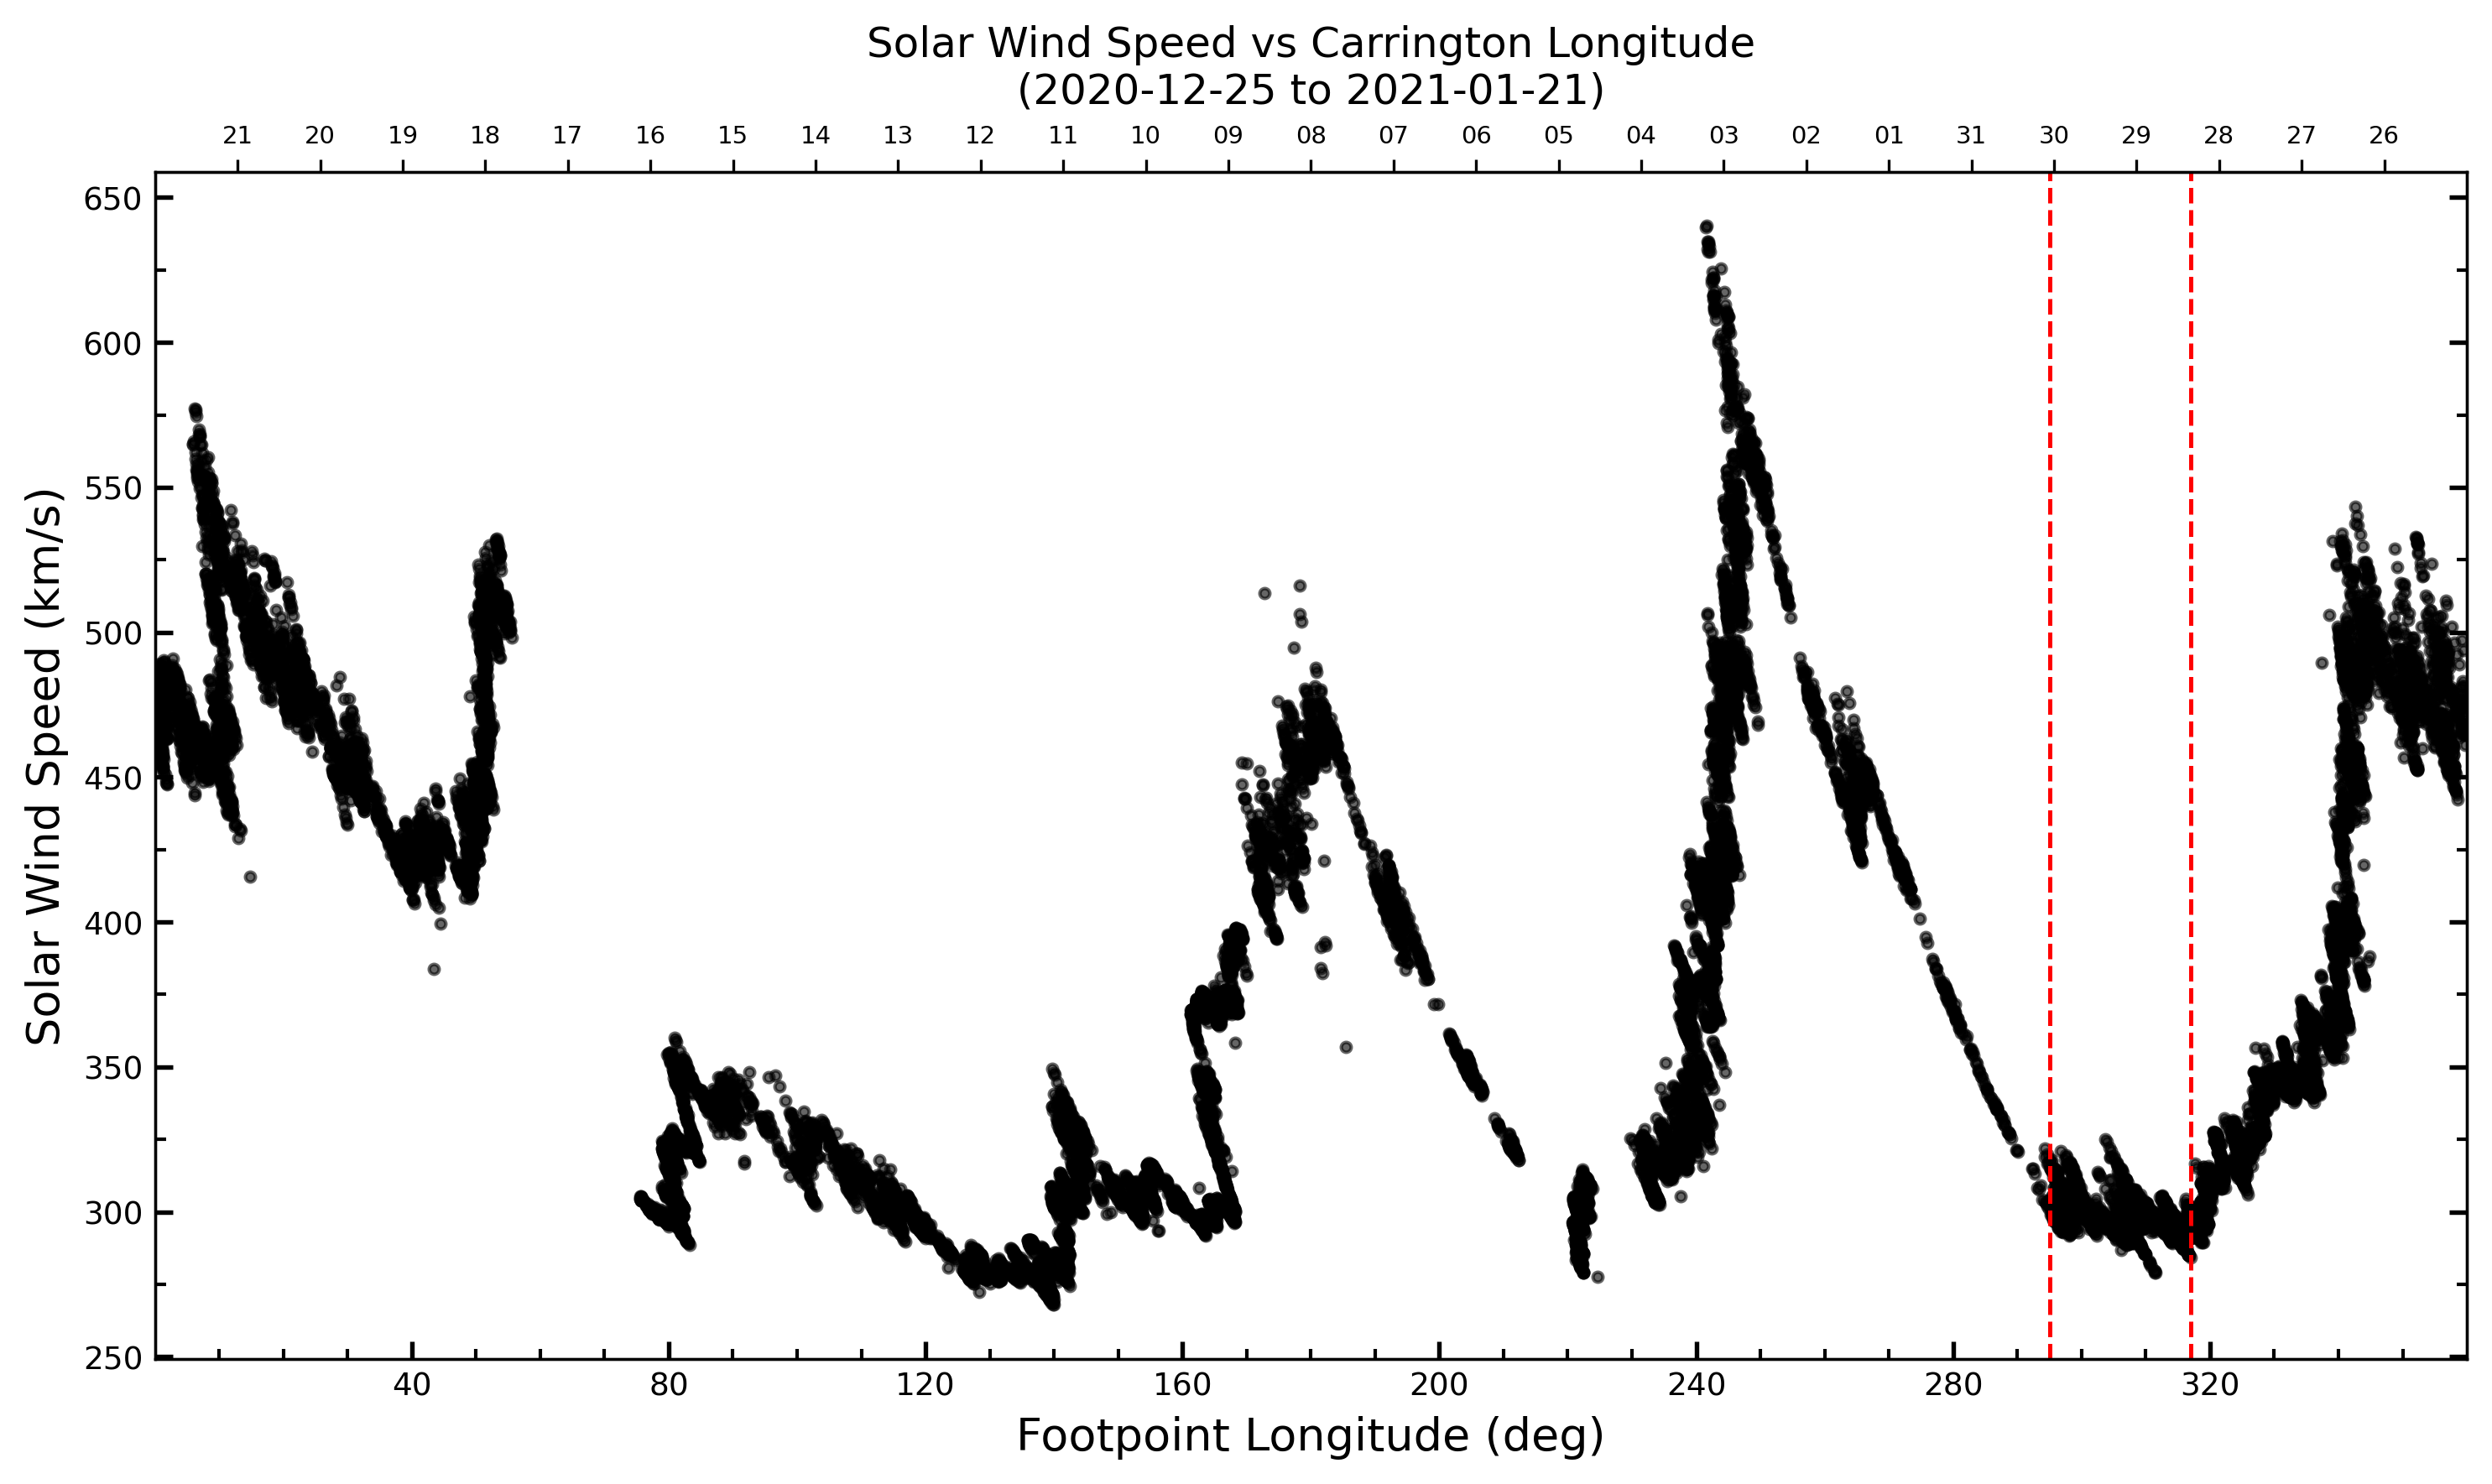

In [ ]:
start_date = df_sel['time'].min().strftime("%Y-%m-%d")
end_date = df_sel['time'].max().strftime("%Y-%m-%d")
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import AutoMinorLocator, MaxNLocator

# Ensure datetime format
df_sel['time'] = pd.to_datetime(
    df_sel['time']
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)


ax.scatter(df_sel['footpoint_lon_deg'],
           df_sel['bulk_speed'],
           s=8, alpha=0.6, color='k', label="WIND data")

ax.set_xlabel("Footpoint Longitude (deg)", fontsize=13)
ax.set_ylabel("Solar Wind Speed (km/s)", fontsize=13)
ax.minorticks_on()
ax.yaxis.set_minor_locator(AutoMinorLocator(2))
ax.tick_params(axis='both', which='major', direction='in', length=5, width=1.3, labelsize=9)
ax.tick_params(axis='both', which='minor', direction='in', length=3, width=1)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('both')

#ax.axhline(y=300, color='red', linestyle='--', linewidth=1.5, alpha=0.8, label='300 km/s threshold')
ax.axvline(x=317, color='r', linestyle='--', lw=1.2, label="Longitude range")
ax.axvline(x=295, color='r', linestyle='--', lw=1.2)

ax.xaxis.set_major_locator(MaxNLocator(10))
ax.set_xlim(min(df_sel['footpoint_lon_deg']),
            max(df_sel['footpoint_lon_deg']))

ax_top = ax.twiny()
formatter = mdates.DateFormatter('%d')   # show only day numbers
ax_top.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax_top.xaxis.set_major_formatter(formatter)


min_time = df_sel['time'].min()
max_time = df_sel['time'].max()
ax_top.set_xlim(max_time, min_time)   # reverse

plt.setp(ax_top.get_xticklabels(), rotation=0, ha='center', fontsize=7)

plt.title(f"Solar Wind Speed vs Carrington Longitude\n({min_time.date()} to {max_time.date()})")
plt.tight_layout()
plt.show()

In [ ]:
pip install mpl-animators>=1.2.0 reproject>=0.12.0

In [ ]:
!pip install sunkit_magex

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.9/60.9 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 372.8/372.8 kB 16.3 MB/s eta 0:00:00


In [ ]:
!pip install pfsspy

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np

import astropy.units as u
from astropy.coordinates import SkyCoord

import sunpy.map
import sunkit_magex.pfss
import sunkit_magex.pfss.tracing as tracing

In [ ]:
filenm ='/content/drive/MyDrive/424ph2013_transferred/ESSW_2026/hmi_maps/hmi.synoptic_mr_720s.2239.synopMr.fits'
hmi_map = sunpy.map.Map(filenm)
#print(hmi_map.meta)

In [ ]:
import numpy as np
import astropy.units as u
import pfsspy
import pfsspy.utils


pfsspy.utils.fix_hmi_meta(hmi_map)

nrho = 35
rss = 2.5


if not pfsspy.utils.is_cea_map(hmi_map):
    hmi_map = pfsspy.utils.car_to_cea(hmi_map)  # reproject Carrington - CEA

hmi_map = hmi_map.resample([360, 180] * u.pix)


data = hmi_map.data
data = np.nan_to_num(data, nan=0.0, posinf=0.0, neginf=0.0)  # replace all bad values with 0
hmi_map = hmi_map._new_instance(data, hmi_map.meta, hmi_map.plot_settings)


pfss_in = pfsspy.Input(hmi_map, nrho, rss)
pfss_out = pfsspy.pfss(pfss_in)


/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^

INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]
INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]
INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]
INFO: Missing metadata for solar radius: assuming the standard radius of the photosphere. [sunpy.map.mapbase]


/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^

Text(0.5, 1.0, 'carr 2239 Source surface magnetic field at 2.5 Rs')

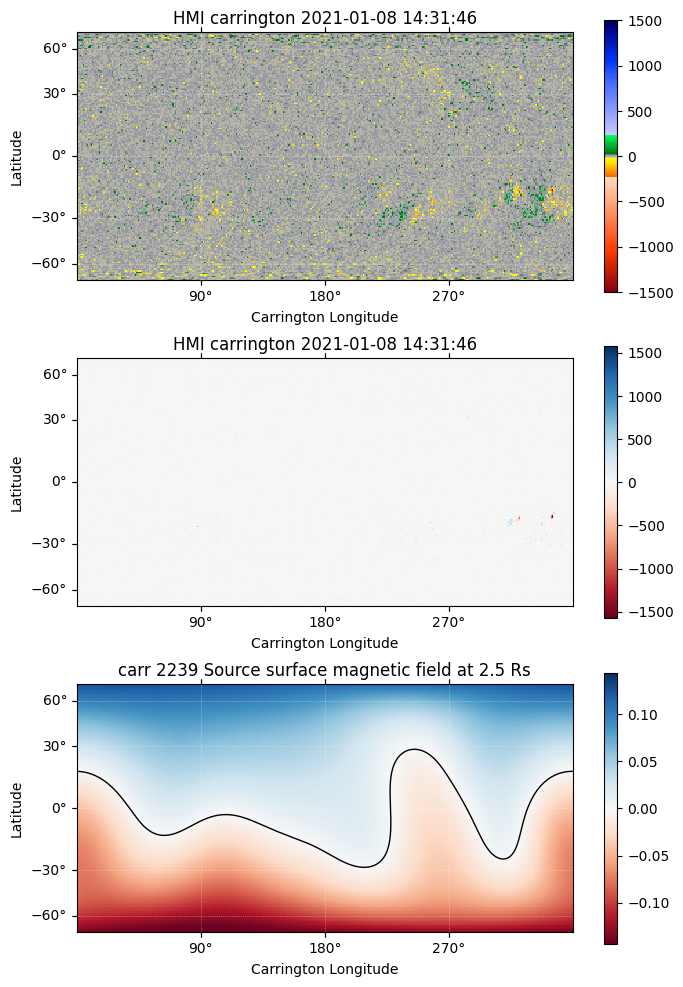

In [ ]:
m=pfss_in.map
ss_br=pfss_out.source_surface_br


fig=plt.figure(figsize=(8,12))
ax=fig.add_subplot(3,1,1,projection=hmi_map)
hmi_map.plot()
plt.colorbar()
ax=fig.add_subplot(3,1,2,projection=m)
m.plot_settings['norm'].vmin = None
m.plot_settings['norm'].vmax = None
ax.set_title('Input HMI magnetogram')
m.plot(axes=ax)
plt.colorbar()
ax=fig.add_subplot(3,1,3,projection=ss_br)
ss_br.plot()
# plot the polarity inversion line
#ax.plot_coord(pfss_out.source_surface_pils[0])
for pil in pfss_out.source_surface_pils:
    ax.plot_coord(pil, color='k', linewidth=1)
plt.colorbar()
ax.set_title("carr "+str(2239)+" Source surface magnetic field at "+str(rss)+" Rs")

/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^

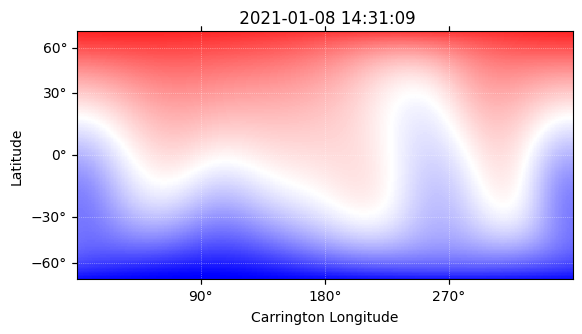

In [ ]:
pfss_out.source_surface_br.plot(cmap='bwr')

In [ ]:
# Define function which does the field line tracing
def pfss2flines(pfsspy_output, # pfsspy output object
                nth=18,nph=36, # number of tracing grid points
                rect=[-90,90,0,360], #sub-region of sun to trace (default is whole sun)
                trace_from_SS=False, # if False : start trace from photosphere,
                                     #if True, start tracing from source surface
                skycoord_in=None, # Use custom set of starting grid poitns
                max_steps = 1000 # max steps tracer should take before giving up
                ) :

    # Tracing if grid
    if skycoord_in is None  :
        [latmin,latmax,lonmin,lonmax]=rect
        lons,lats = np.meshgrid(np.linspace(lonmin,lonmax,nph),
                                np.linspace(latmin,latmax,nth)
                                )
        if not trace_from_SS : alt = 1.0*u.R_sun # Trace up from photosphere
        else : alt = pfsspy_output.grid.rss*u.R_sun  # Trace down from ss
        alt = [alt]*len(lons.ravel())
        seeds = astropy.coordinates.SkyCoord(lons.ravel()*u.deg,
                               lats.ravel()*u.deg,
                               alt,
                               frame = pfsspy_output.coordinate_frame)

    # Tracing if custom set of points
    else :
        skycoord_in.representation_type = "spherical"
        seeds = astropy.coordinates.SkyCoord(skycoord_in.lon,
                               skycoord_in.lat,
                               skycoord_in.radius,
                               frame = pfsspy_output.coordinate_frame)

    return pfsspy_output.trace(pfsspy.tracing.FortranTracer(max_steps=max_steps),seeds)

In [ ]:
# from astropy.coordinates import SkyCoord
import astropy.coordinates
# flines_highres = pfss2flines(pfss_out,nth=180,nph=360,rect=[-89.5,89.5,0.5,359.5])
flines_highres = pfss2flines(pfss_out,nth=181,nph=361)

/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/tracing.py:180: UserWarning: At least one field line ran out of steps during tracing.
You should probably increase max_steps (currently set to 1000) and try again.
  warnings.warn(


In [ ]:
topologies = flines_highres.polarities.reshape([181,361])

Text(0.5, 1.0, 'Coronal Hole Map Rss=2.5Rs')

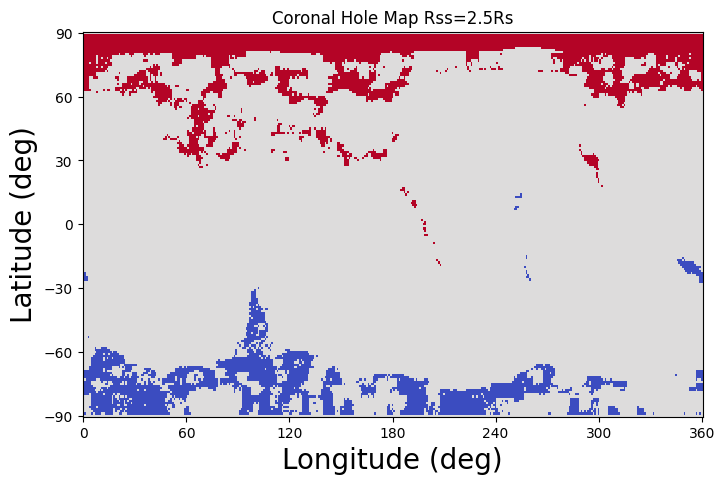

In [ ]:
lons = np.linspace(0,360,361)
lats = np.linspace(-90,90,181)
fig,ax = plt.subplots(figsize=(8,5))
ax.pcolormesh(lons,lats,topologies,cmap="coolwarm")
ax.set_xlabel("Longitude (deg)",fontsize=20)
ax.set_ylabel("Latitude (deg)",fontsize=20)
ax.set_xticks(np.linspace(0,360,7))
ax.set_yticks(np.linspace(-90,90,7))
ax.set_title(f"Coronal Hole Map Rss=2.5Rs")

In [ ]:
def source_surface_seeds(n_lon=92, n_lat=41, obstime=None):
    lon = np.linspace(0, 360, n_lon, endpoint=False)
    lat = np.arcsin(np.linspace(-0.5, 0.5, n_lat))
    lon_grid, lat_grid = np.meshgrid(lon, lat,indexing='ij')
    r = np.full_like(lat_grid, 2.5)
    return SkyCoord(
        lon_grid.flatten() * u.deg,
        lat_grid.flatten() * u.deg,
        r.flatten() * u.R_sun,
        frame='heliographic_carrington',
        obstime=obstime,
        observer='sun'
    )

tracer =pfsspy.tracing.FortranTracer(max_steps=8000,step_size=0.1)
seeds_all = source_surface_seeds(n_lon=92, n_lat=41, obstime=hmi_map.date)
flines = tracer.trace(seeds_all, pfss_out)

/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^

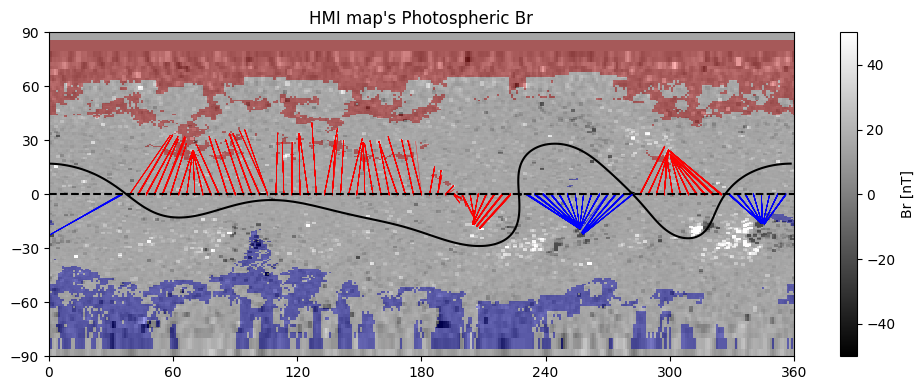

In [ ]:
from datetime import datetime, timedelta
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u

# Get longitude and latitude from PFSS output
lon = np.degrees(pfss_out.grid.pg)
lat = np.degrees(np.arcsin(pfss_out.grid.sg))
lon2, lat2 = np.meshgrid(lon, lat)

# Create the figure
fig, axes = plt.subplots(figsize=(10, 4))
axes.set_title("HMI map's Photospheric Br")

# Plot photospheric Br
c = axes.pcolor(
    lon, lat, pfss_out.bg[:, :, 0, 2].T,
    cmap='gray', norm=None,
    vmin=-50, vmax=50, shading='nearest'
)

# Plot Br=0 contour (neutral line / HCS)
axes.contour(
    lon[:-1], lat[:-1], pfss_out.source_surface_br.data,
    levels=[0], colors='k', linewidths=1.5
)

# Add colorbar
plt.colorbar(c, ax=axes, label="Br [nT]", orientation='vertical')

# Overlay topology map
axes.pcolormesh(lon2, lat2, topologies, cmap="bwr", alpha=0.3)

#  Polarity color mapping
color_dict = {-1: 'blue', 0: 'black', 1: 'red'}

# Plot magnetic field lines
for fline in flines:
    coords = fline.coords
    if len(coords.lon) == 0 or len(coords.lat) == 0:
        continue  # skip empty field lines

    # Convert coordinates
    lon_vals = coords.lon.to(u.deg).value % 360
    lat_vals = coords.lat.to(u.deg).value

    # Get polarity
    polarity = getattr(fline, "polarity", 0)
    color = color_dict.get(polarity, 'black')

    # Avoid wrap-around issue
    if np.abs(lon_vals[0] - lon_vals[-1]) < 200:
        axes.plot(
    [lon_vals[0], lon_vals[-1]],
    [lat_vals[0], lat_vals[-1]],
    color=color, lw=0.3, alpha=0.8
)

# Add equator line and axes formatting
plt.axhline(y=0, color='k', linestyle='--')
axes.set_xticks(np.linspace(0, 360, 7))
axes.set_yticks(np.linspace(-90, 90, 7))
axes.set_xlim([0, 360])
axes.set_ylim([-90, 90])

plt.tight_layout()
plt.show()

/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^2" as a valid FITS unit.
See https://fits.gsfc.nasa.gov/fits_standard.html for the FITS unit standards.
  warnings.warn(f'Could not parse unit string "{unit_str}" as a valid FITS unit.\n'
/usr/local/lib/python3.12/dist-packages/pfsspy/output.py:95: UserWarning: Could not parse unit string "Mx/cm^

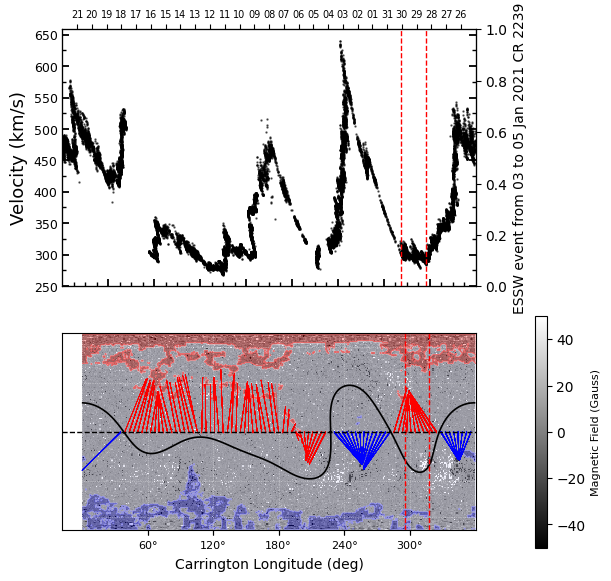

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import AutoMinorLocator, MaxNLocator
import astropy.units as u
import matplotlib.colors as mcolor
from astropy.coordinates import SkyCoord
from astropy.visualization.wcsaxes import formatter_locator

# === FIGURE 1: Velocity vs Footpoint Longitude ===
fig = plt.figure(figsize=(6, 6), constrained_layout=True)

# --- Upper panel ---
ax = fig.add_subplot(2, 1, 1)
ax.scatter(
    df_sel['footpoint_lon_deg'],
    df_sel['bulk_speed'],
    color='k', alpha=0.6, s=0.5
)

ax.set_xticklabels([])
ax.set_ylabel('Velocity (km/s)', fontsize=13)

# Twin y-axis
ax_right = ax.twinx()
ax_right.set_ylabel("ESSW event from 03 to 05 Jan 2021 CR 2239", fontsize=10)

# Tick formatting
ax.minorticks_on()
ax.yaxis.set_minor_locator(AutoMinorLocator(2))
ax.tick_params(axis='both', which='major', direction='in', length=5, width=1.3, labelsize=9)
ax.tick_params(axis='both', which='minor', direction='in', length=3, width=1)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('both')

# Vertical markers
plt.axvline(x=317, color='r', linestyle='--', lw=1)
plt.axvline(x=295, color='r', linestyle='--', lw=1)

# Limits
ax.xaxis.set_major_locator(MaxNLocator(10))
ax.set_xlim(
    min(df_sel['footpoint_lon_deg']),
    max(df_sel['footpoint_lon_deg'])
)

# Twin x-axis (dates)
ax_top = ax.twiny()
formatter = mdates.DateFormatter('%d')
ax_top.xaxis.set_major_locator(MaxNLocator(29))
ax_top.xaxis.set_major_formatter(formatter)

min_time = df_sel['time'].min()
max_time = df_sel['time'].max()
ax_top.set_xlim(max_time, min_time)
plt.setp(ax_top.get_xticklabels(), rotation=0, ha='center', fontsize=7)

# === FIGURE 2: PFSS / HMI Map ===
ax2 = fig.add_subplot(2, 1, 2, projection=hmi_map)

# Neutral line (HCS)
#if hasattr(pfss_out, 'source_surface_pils') and len(pfss_out.source_surface_pils) > 0:
#    ax2.plot_coord(pfss_out.source_surface_pils[0], color='k', linewidth=1)
if hasattr(pfss_out, 'source_surface_pils') and len(pfss_out.source_surface_pils) > 0:
    for pil in pfss_out.source_surface_pils:
        if pil is None or len(pil.lon) == 0:
            continue
        try:
            ax2.plot_coord(pil, color='k', linewidth=1.2)
        except Exception:
            continue

# HMI background
im = hmi_map.plot(axes=ax2, cmap='gray', norm=None, vmin=-50.0, vmax=50.0)

# Colorbar
cbar = fig.colorbar(im, pad=0.02, shrink=0.9, ax=ax2)
cbar.set_label('Magnetic Field (Gauss)', size=8)

# Topology overlay
ax2.contourf(topologies, cmap='bwr', norm=None, alpha=0.3)

# Polarity mapping
color_dict = {-1: 'blue', 0: 'black', 1: 'red'}

# Field lines
for fline in flines:
    coords = fline.coords
    if len(coords.lon) == 0 or len(coords.lat) == 0:
        continue

    lon_start = coords.lon[0].to(u.deg).value
    lat_start = coords.lat[0].to(u.deg).value
    lon_end   = coords.lon[-1].to(u.deg).value
    lat_end   = coords.lat[-1].to(u.deg).value

    polarity = getattr(fline, "polarity", 0)
    color = color_dict.get(polarity, 'black')

    # Avoid wrap-around
    if np.abs(lon_start - lon_end) < 200:
        try:
            ax2.plot_coord(
                SkyCoord(
                    [lon_start, lon_end],
                    [lat_start, lat_end],
                    unit='deg',
                    frame=hmi_map.coordinate_frame
                ),
                color=color,
                linewidth=0.3,   #thinner lines
                alpha=0.8
            )
        except Exception:
            continue

# Coordinate formatting
lon = ax2.coords[0]
lat = ax2.coords[1]

lon.set_ticks([0, 60, 120, 180, 240, 300, 360] * u.deg)
lon.set_ticklabel_position('b')
lon.set_ticklabel(size=8)
lon.set_axislabel("Carrington Longitude (deg)", fontsize=10)
lon.set_major_formatter('d')

lat.set_ticks([-90, -60, -30, 0, 30, 60, 90] * u.deg)
lat.set_ticklabel(size=8)
lat.set_axislabel("Carrington Latitude (deg)", fontsize=10)
lat.set_major_formatter('d')

# Markers
ax2.set_title("")
ax2.axvline(x=(317 * u.deg).value, color='red', linestyle='--', linewidth=1)
ax2.axvline(x=(295* u.deg).value, color='red', linestyle='--', linewidth=1)
ax2.axhline(y=90, color='black', linestyle='--', linewidth=1)

plt.show()